<div style='background:#1a3a5c; padding:20px; border-radius:10px; color:white;'>
<h1>💧 Detección de Agua No Apta mediante Aprendizaje Automático</h1>
<h3>Metodología CRISP-ML(Q) — Dataset: Calidad del Agua IRCA</h3>
<p>Taller Final</p>
</div>

---
## Contexto del Problema

El **Índice de Riesgo de la Calidad del Agua (IRCA)** es un indicador colombiano que clasifica el agua según su riesgo para la salud humana. Un IRCA = 0 indica agua apta; cualquier valor mayor indica riesgo.

El dataset contiene **1.718 muestras** de agua recolectadas desde 2012, con parámetros fisicoquímicos y microbiológicos. El dataset está **fuertemente desbalanceado**: solo el ~2.5% de las muestras son no aptas.

**Objetivo:** Clasificar automáticamente si una muestra es **Apta (0)** o **No Apta (1)** usando aprendizaje supervisado.

### Fases CRISP-ML(Q)
1. Comprensión del negocio
2. Comprensión de los datos (EDA)
3. Preparación de los datos
4. Modelamiento (3 modelos)
5. Evaluación y comparación
6. Despliegue (app Streamlit)

---
## Imports

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score,
    classification_report, confusion_matrix, roc_curve, auc, ConfusionMatrixDisplay
)
from imblearn.over_sampling import SMOTE

print('Librerias cargadas correctamente')

Librerias cargadas correctamente


## Funciones Auxiliares

In [2]:
def train_val_test_split(X, y, rstate=42):
    """Division 60% train / 20% validacion / 20% test con estratificacion."""
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.4, random_state=rstate, stratify=y)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.5, random_state=rstate, stratify=y_temp)
    return X_train, X_val, X_test, y_train, y_val, y_test

def evaluar_modelo(nombre, modelo, X_eval, y_eval):
    """Calcula y muestra las 4 metricas principales."""
    pred = modelo.predict(X_eval)
    acc  = accuracy_score(y_eval, pred)
    f1   = f1_score(y_eval, pred, average='weighted')
    prec = precision_score(y_eval, pred, average='weighted', zero_division=0)
    rec  = recall_score(y_eval, pred, average='weighted')
    print(f"  {'Accuracy':<12}: {acc:.4f}")
    print(f"  {'F1 Score':<12}: {f1:.4f}")
    print(f"  {'Precision':<12}: {prec:.4f}")
    print(f"  {'Recall':<12}: {rec:.4f}")
    return {'Modelo': nombre, 'Accuracy': acc, 'F1': f1, 'Precision': prec, 'Recall': rec}

print('Funciones auxiliares definidas')

Funciones auxiliares definidas


---
## Fase 1 - Comprension del Negocio

| Elemento | Descripcion |
|---|---|
| **Problema** | Clasificar muestras de agua como aptas o no aptas |
| **Variable objetivo** | `IRCA_label`: 0 = Apta, 1 = No apta |
| **Impacto** | Alertas tempranas de riesgo para la salud publica |
| **Restriccion** | Dataset desbalanceado (~2.5% de clase positiva) |
| **Metrica de exito** | F1-Score + Recall en clase No Apta |

---
## Fase 2 - Comprension de los Datos (EDA)
### 2.1 Lectura del dataset

In [3]:
df_raw = pd.read_csv('CALIDAD_DEL_AGUA_20260516.csv')
print(f'Numero de registros: {len(df_raw)}')
print(f'Numero de columnas:  {len(df_raw.columns)}')
df_raw.head(5)

Numero de registros: 1718
Numero de columnas:  23


,Fecha de Toma de Muestra,Hora de Toma de Muestra,Fecha de Entrega al Laboratorio,Código de la Muestra,NSPM,Código del Laboratorio,Tipo de Muestra,Clasificación de la Muestra,Color Aparente,Turbiedad,...,Hierro Total,Cloruros,Alcalinidad,Sulfatos,Nitratos,Coliformes Totales,Técnica Empleada para la Determinación de los Coliformes Totales,Escherichia Coli,Técnica Empleada para la Determinación de la Escherichia Coli,Resultados del IRCA por Muestra
0,2012 Jan 01 12:00:00 AM,1899-12-31T10:05:00.000,2012 Jan 01 12:00:00 AM,0001-1,2.0,NaN,2,2,"8,7","1,18",...,NaN,NaN,NaN,NaN,NaN,0.0,1,0.0,0.0,0
1,2012 Jan 01 12:00:00 AM,1899-12-31T10:22:00.000,2012 Jan 01 12:00:00 AM,0001-2,15.0,NaN,2,2,"3,2","0,6",...,NaN,NaN,NaN,NaN,NaN,0.0,1,0.0,0.0,0
2,2012 Jan 01 12:00:00 AM,1899-12-31T10:34:00.000,2012 Jan 01 12:00:00 AM,0001-3,20.0,NaN,2,2,"3,4","0,55",...,NaN,NaN,NaN,NaN,NaN,1.0,1,0.0,0.0,"19,35"
3,2012 Jan 02 12:00:00 AM,1899-12-31T09:48:00.000,2012 Jan 02 12:00:00 AM,0004-1,4.0,NaN,2,2,"8,4","0,91",...,NaN,NaN,NaN,NaN,NaN,0.0,1,0.0,0.0,0
4,2012 Jan 02 12:00:00 AM,1899-12-31T09:26:00.000,2012 Jan 02 12:00:00 AM,0004-2,7.0,NaN,2,2,24,"3,03",...,NaN,NaN,NaN,NaN,NaN,0.0,1,0.0,0.0,"27,1"


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 1718 entries, 0 to 1717
Data columns (total 23 columns):
 #   Column                                                            Non-Null Count  Dtype  
---  ------                                                            --------------  -----  
 0   Fecha de Toma de Muestra                                          1718 non-null   str    
 1   Hora de Toma de Muestra                                           1718 non-null   str    
 2   Fecha de Entrega al Laboratorio                                   1718 non-null   str    
 3   Código de la Muestra                                              1718 non-null   str    
 4   NSPM                                                              1718 non-null   float64
 5   Código del Laboratorio                                            1366 non-null   float64
 6   Tipo de Muestra                                                   1718 non-null   int64  
 7   Clasificación de la Muestra                 

### 2.2 Seleccion y conversion de variables numericas

In [5]:
FEATURES = ['Color Aparente', 'Turbiedad', 'pH', 'Cloro Residual Libre', 'Coliformes Totales']

df = pd.DataFrame()
for col in FEATURES:
    df[col] = pd.to_numeric(df_raw[col].astype(str).str.replace(',', '.'), errors='coerce')

irca_num = pd.to_numeric(
    df_raw['Resultados del IRCA por Muestra'].astype(str).str.replace(',', '.'), errors='coerce'
)
df['IRCA_label'] = (irca_num > 0).astype(int)

df_limpio = df.dropna().reset_index(drop=True)
print(f'Registros tras limpieza: {len(df_limpio)}')
df_limpio.head()

Registros tras limpieza: 1711


,Color Aparente,Turbiedad,pH,Cloro Residual Libre,Coliformes Totales,IRCA_label
0,8.7,1.18,7.10,1.48,0.0,0
1,3.2,0.60,7.14,1.18,0.0,0
2,3.4,0.55,7.21,1.77,1.0,1
3,8.4,0.91,7.10,1.42,0.0,0
4,24.0,3.03,7.17,1.52,0.0,1


### 2.3 Valores nulos y estadisticas descriptivas

In [6]:
print('=== Valores nulos por columna ===')
print(df[FEATURES + ['IRCA_label']].isna().sum())

=== Valores nulos por columna ===
Color Aparente          0
Turbiedad               0
pH                      2
Cloro Residual Libre    2
Coliformes Totales      5
IRCA_label              0
dtype: int64


In [7]:
df_limpio.describe().round(3)

,Color Aparente,Turbiedad,pH,Cloro Residual Libre,Coliformes Totales,IRCA_label
count,1711.000,1711.000,1711.000,1711.000,1711.000,1711.000
mean,5.133,0.549,7.016,1.504,0.011,0.025
std,3.927,0.483,0.189,0.213,0.125,0.157
min,1.600,0.050,6.330,0.300,0.000,0.000
25%,2.500,0.205,6.890,1.380,0.000,0.000
50%,3.500,0.400,7.020,1.530,0.000,0.000
75%,6.050,0.700,7.140,1.640,0.000,0.000
max,33.600,3.860,7.900,2.000,2.000,1.000


### 2.4 Distribucion de la variable objetivo

IRCA_label
0    1668
1      43
Name: count, dtype: int64

Porcentaje de muestras NO aptas: 2.51%


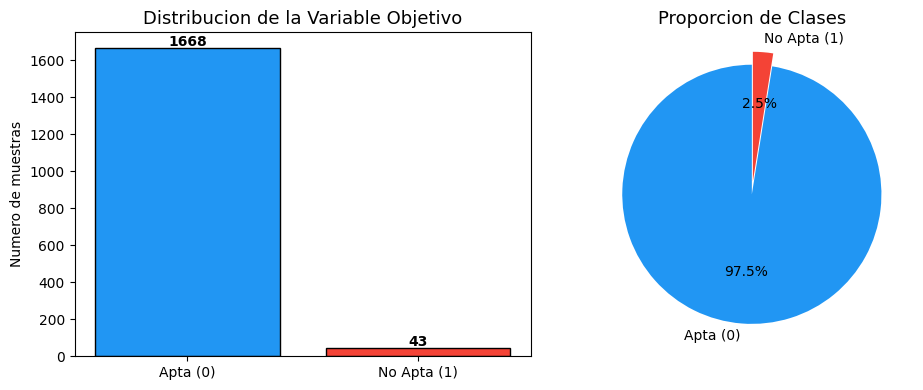

In [8]:
conteo = df_limpio['IRCA_label'].value_counts()
print(conteo)
print(f'\nPorcentaje de muestras NO aptas: {df_limpio["IRCA_label"].mean()*100:.2f}%')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(['Apta (0)', 'No Apta (1)'], conteo.values, color=['#2196F3', '#F44336'], edgecolor='black')
axes[0].set_title('Distribucion de la Variable Objetivo', fontsize=13)
axes[0].set_ylabel('Numero de muestras')
for i, v in enumerate(conteo.values):
    axes[0].text(i, v + 10, str(v), ha='center', fontweight='bold')

axes[1].pie(conteo.values, labels=['Apta (0)', 'No Apta (1)'],
            autopct='%1.1f%%', colors=['#2196F3', '#F44336'],
            startangle=90, explode=[0, 0.1])
axes[1].set_title('Proporcion de Clases', fontsize=13)

plt.tight_layout()
plt.show()

### 2.5 Analisis Univariable - Distribucion por clase

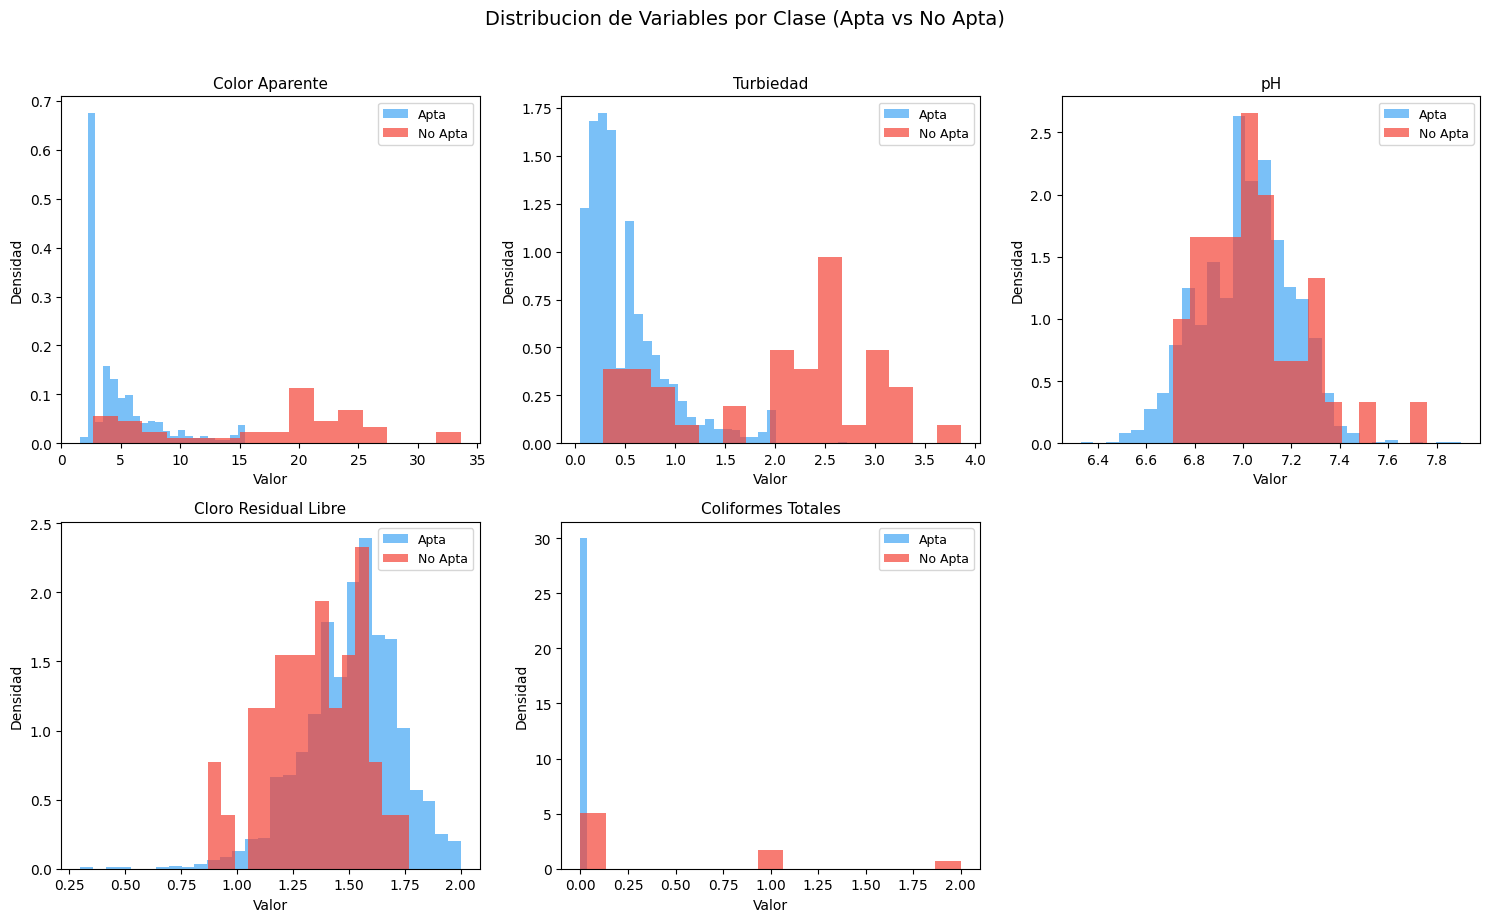

In [9]:
aptas    = df_limpio[df_limpio['IRCA_label'] == 0]
no_aptas = df_limpio[df_limpio['IRCA_label'] == 1]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, feat in enumerate(FEATURES):
    axes[i].hist(aptas[feat], bins=30, alpha=0.6, color='#2196F3', label='Apta', density=True)
    axes[i].hist(no_aptas[feat], bins=15, alpha=0.7, color='#F44336', label='No Apta', density=True)
    axes[i].set_title(f'{feat}', fontsize=11)
    axes[i].set_xlabel('Valor')
    axes[i].set_ylabel('Densidad')
    axes[i].legend(fontsize=9)

axes[5].axis('off')
plt.suptitle('Distribucion de Variables por Clase (Apta vs No Apta)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### 2.6 Analisis Bivariable - Diagramas de dispersion

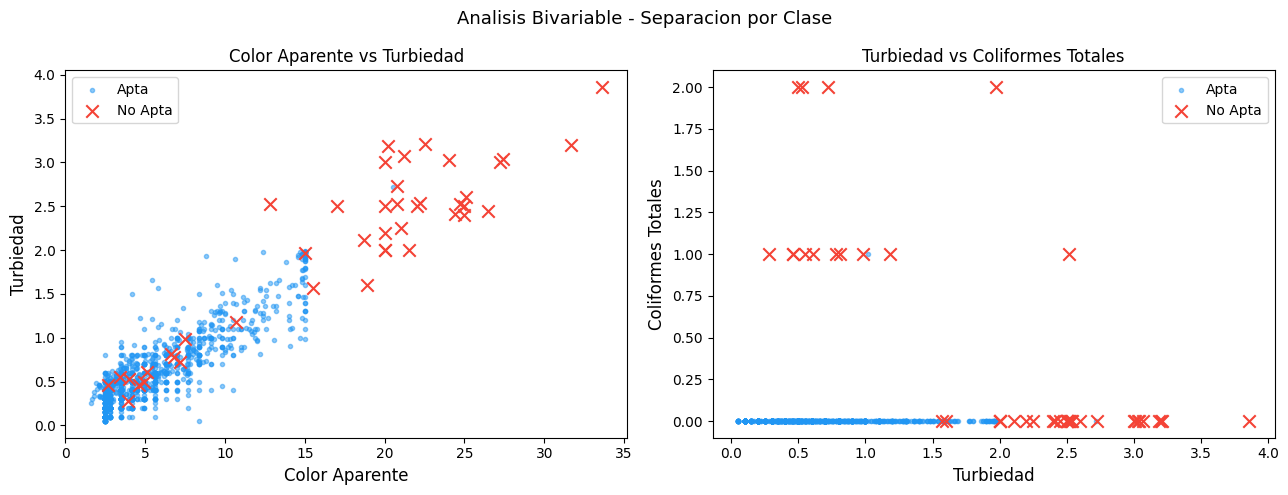

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(aptas['Color Aparente'], aptas['Turbiedad'],
                c='#2196F3', marker='.', alpha=0.5, label='Apta')
axes[0].scatter(no_aptas['Color Aparente'], no_aptas['Turbiedad'],
                c='#F44336', marker='x', s=80, label='No Apta')
axes[0].set_xlabel('Color Aparente', fontsize=12)
axes[0].set_ylabel('Turbiedad', fontsize=12)
axes[0].set_title('Color Aparente vs Turbiedad', fontsize=12)
axes[0].legend()

axes[1].scatter(aptas['Turbiedad'], aptas['Coliformes Totales'],
                c='#2196F3', marker='.', alpha=0.5, label='Apta')
axes[1].scatter(no_aptas['Turbiedad'], no_aptas['Coliformes Totales'],
                c='#F44336', marker='x', s=80, label='No Apta')
axes[1].set_xlabel('Turbiedad', fontsize=12)
axes[1].set_ylabel('Coliformes Totales', fontsize=12)
axes[1].set_title('Turbiedad vs Coliformes Totales', fontsize=12)
axes[1].legend()

plt.suptitle('Analisis Bivariable - Separacion por Clase', fontsize=13)
plt.tight_layout()
plt.show()

### 2.7 Analisis Multivariable - Matriz de Correlacion

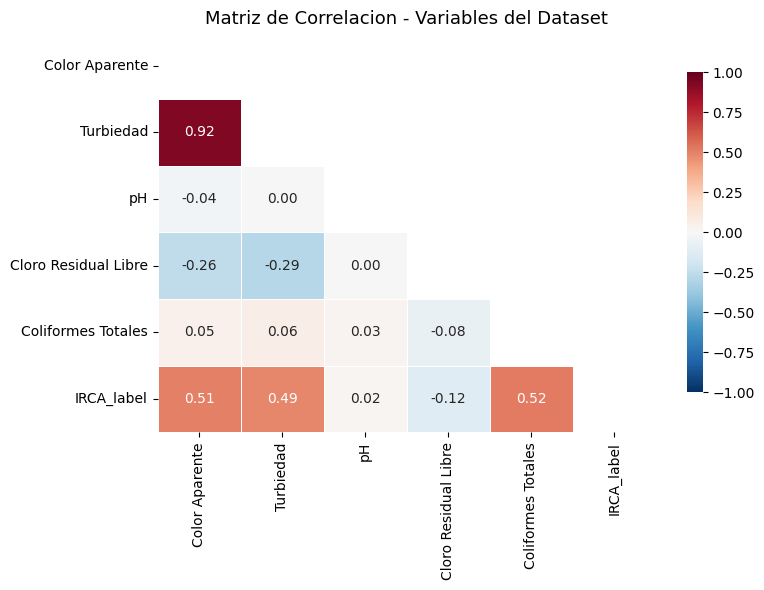

In [11]:
corr = df_limpio.corr()

plt.figure(figsize=(8, 6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r',
            mask=mask, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Matriz de Correlacion - Variables del Dataset', fontsize=13)
plt.tight_layout()
plt.show()

=== Correlacion con IRCA_label ===
Coliformes Totales      0.523
Color Aparente          0.505
Turbiedad               0.489
pH                      0.016
Cloro Residual Libre   -0.121
Name: IRCA_label, dtype: float64


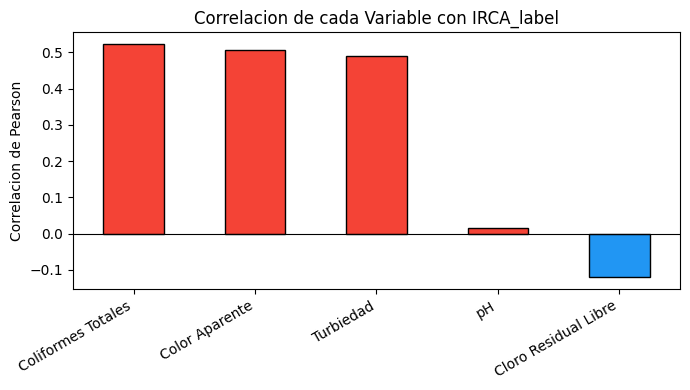

In [12]:
corr_target = corr['IRCA_label'].drop('IRCA_label').sort_values(ascending=False)
print('=== Correlacion con IRCA_label ===')
print(corr_target.round(3))

plt.figure(figsize=(7, 4))
colors = ['#F44336' if v > 0 else '#2196F3' for v in corr_target.values]
corr_target.plot(kind='bar', color=colors, edgecolor='black')
plt.title('Correlacion de cada Variable con IRCA_label', fontsize=12)
plt.ylabel('Correlacion de Pearson')
plt.xticks(rotation=30, ha='right')
plt.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

### 2.8 Boxplots - Distribucion por clase

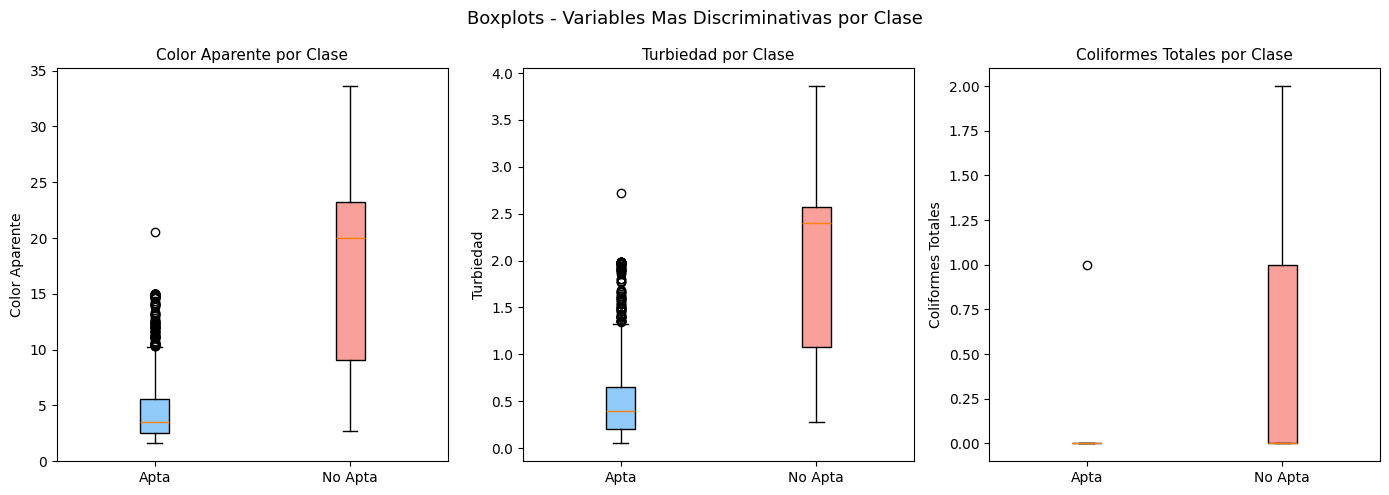

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for i, feat in enumerate(['Color Aparente', 'Turbiedad', 'Coliformes Totales']):
    data_box = [aptas[feat].values, no_aptas[feat].values]
    bp = axes[i].boxplot(data_box, labels=['Apta', 'No Apta'],
                         patch_artist=True, notch=False)
    bp['boxes'][0].set_facecolor('#2196F380')
    bp['boxes'][1].set_facecolor('#F4433680')
    axes[i].set_title(f'{feat} por Clase', fontsize=11)
    axes[i].set_ylabel(feat)

plt.suptitle('Boxplots - Variables Mas Discriminativas por Clase', fontsize=13)
plt.tight_layout()
plt.show()

---
## Fase 3 - Preparacion de los Datos
### 3.1 Division del dataset (Train / Validacion / Test)

In [14]:
X = df_limpio[FEATURES].copy()
y = df_limpio['IRCA_label'].copy()

X_train, X_val, X_test, y_train, y_val, y_test = train_val_test_split(X, y)

print(f'Train:      {len(X_train)} muestras - No aptas: {y_train.sum()}')
print(f'Validacion: {len(X_val)} muestras - No aptas: {y_val.sum()}')
print(f'Test:       {len(X_test)} muestras - No aptas: {y_test.sum()}')

Train:      1026 muestras - No aptas: 26
Validacion: 342 muestras - No aptas: 8
Test:       343 muestras - No aptas: 9


### 3.2 Escalado con RobustScaler

In [15]:
scaler = RobustScaler()
X_train_s = scaler.fit_transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

print('Estadisticas despues del escalado (Train):')
pd.DataFrame(X_train_s, columns=FEATURES).describe().round(3)

Estadisticas despues del escalado (Train):


,Color Aparente,Turbiedad,pH,Cloro Residual Libre,Coliformes Totales
count,1026.000,1026.000,1026.000,1026.000,1026.000
mean,0.457,0.362,-0.021,-0.070,0.011
std,1.048,1.097,0.733,0.795,0.128
min,-0.500,-0.778,-2.654,-4.519,0.000
25%,-0.263,-0.333,-0.538,-0.556,0.000
50%,0.000,0.000,0.000,0.000,0.000
75%,0.737,0.667,0.462,0.444,0.000
max,7.921,7.689,3.385,1.778,2.000


### 3.3 Balanceo con SMOTE

=== Antes de SMOTE ===
{0: 1000, 1: 26}

=== Despues de SMOTE ===
{0: 1000, 1: 1000}


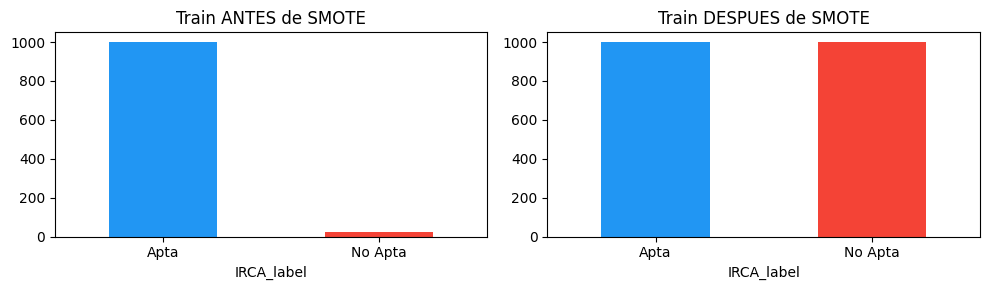

In [16]:
sm = SMOTE(random_state=42, k_neighbors=3)
X_train_sm, y_train_sm = sm.fit_resample(X_train_s, y_train)

print('=== Antes de SMOTE ===')
print(y_train.value_counts().to_dict())
print('\n=== Despues de SMOTE ===')
print(pd.Series(y_train_sm).value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
y_train.value_counts().plot(kind='bar', ax=axes[0], color=['#2196F3','#F44336'],
                             title='Train ANTES de SMOTE', rot=0)
pd.Series(y_train_sm).value_counts().plot(kind='bar', ax=axes[1], color=['#2196F3','#F44336'],
                                           title='Train DESPUES de SMOTE', rot=0)
for ax in axes:
    ax.set_xticklabels(['Apta', 'No Apta'])
plt.tight_layout()
plt.show()

### 3.4 Importancia de Caracteristicas con Random Forest

=== Importancia de Caracteristicas ===
Color Aparente          0.4040
Turbiedad               0.3164
Coliformes Totales      0.2242
Cloro Residual Libre    0.0380
pH                      0.0175
dtype: float64


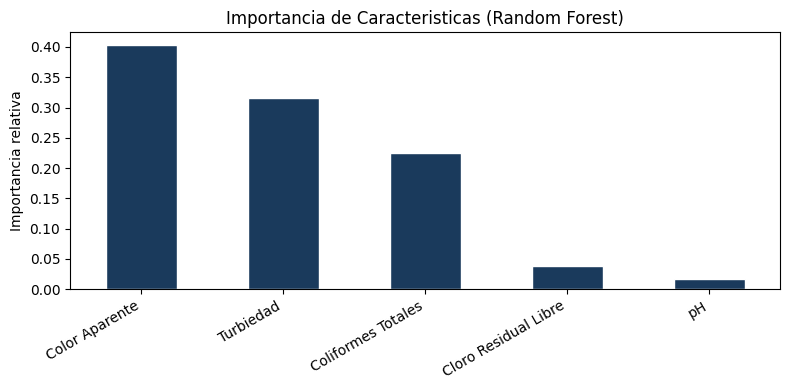

In [17]:
rf_feat = RandomForestClassifier(n_estimators=100, random_state=42)
rf_feat.fit(X_train_sm, y_train_sm)

feature_importances = pd.Series(rf_feat.feature_importances_, index=FEATURES).sort_values(ascending=False)
print('=== Importancia de Caracteristicas ===')
print(feature_importances.round(4))

plt.figure(figsize=(8, 4))
feature_importances.plot(kind='bar', color='#1a3a5c', edgecolor='white')
plt.title('Importancia de Caracteristicas (Random Forest)', fontsize=12)
plt.ylabel('Importancia relativa')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

---
## Fase 4 - Modelamiento

| Modelo | Descripcion |
|---|---|
| **Regresion Logistica** | Modelo base lineal, interpretable, rapido |
| **Random Forest** | Ensemble de arboles, robusto con datos complejos |
| **XGBoost** | Gradient boosting, generalmente el mas preciso |

### 4.1 Modelo 1: Regresion Logistica

In [18]:
lr = LogisticRegression(random_state=42, max_iter=1000)
lr.fit(X_train_sm, y_train_sm)
print('=== Regresion Logistica - Validacion ===')
res_lr = evaluar_modelo('Regresion Logistica', lr, X_val_s, y_val)

=== Regresion Logistica - Validacion ===
  Accuracy    : 0.9825
  F1 Score    : 0.9848
  Precision   : 0.9900
  Recall      : 0.9825


### 4.2 Modelo 2: Random Forest

In [19]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_sm, y_train_sm)
print('=== Random Forest - Validacion ===')
res_rf = evaluar_modelo('Random Forest', rf, X_val_s, y_val)

=== Random Forest - Validacion ===
  Accuracy    : 0.9971
  F1 Score    : 0.9972
  Precision   : 0.9974
  Recall      : 0.9971


### 4.3 Modelo 3: XGBoost

In [20]:
xgb = XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss', verbosity=0)
xgb.fit(X_train_sm, y_train_sm)
print('=== XGBoost - Validacion ===')
res_xgb = evaluar_modelo('XGBoost', xgb, X_val_s, y_val)

=== XGBoost - Validacion ===
  Accuracy    : 0.9971
  F1 Score    : 0.9972
  Precision   : 0.9974
  Recall      : 0.9971


---
## Fase 5 - Evaluacion y Comparacion de Modelos
### 5.1 Tabla comparativa de metricas

In [21]:
resultados = pd.DataFrame([res_lr, res_rf, res_xgb]).set_index('Modelo')
print('=== Comparacion de Modelos (Validacion) ===')
print(resultados.round(4).to_string())
resultados.round(4)

=== Comparacion de Modelos (Validacion) ===
                     Accuracy      F1  Precision  Recall
Modelo                                                  
Regresion Logistica    0.9825  0.9848     0.9900  0.9825
Random Forest          0.9971  0.9972     0.9974  0.9971
XGBoost                0.9971  0.9972     0.9974  0.9971


,Accuracy,F1,Precision,Recall
Modelo,,,,
Regresion Logistica,0.9825,0.9848,0.9900,0.9825
Random Forest,0.9971,0.9972,0.9974,0.9971
XGBoost,0.9971,0.9972,0.9974,0.9971


### 5.2 Visualizacion comparativa

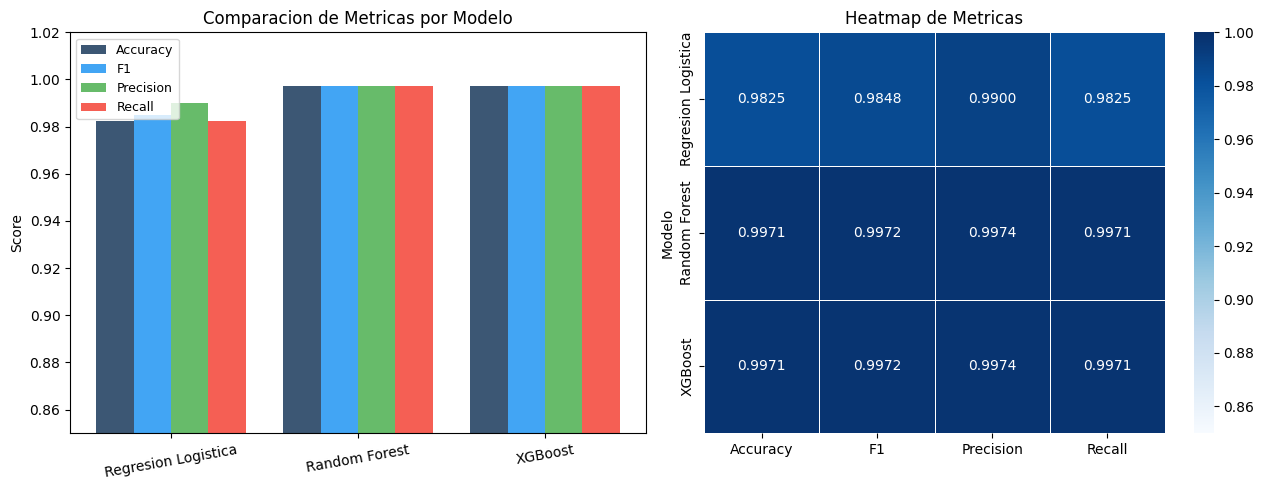

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x = np.arange(len(resultados))
width = 0.2
metricas = ['Accuracy', 'F1', 'Precision', 'Recall']
colors_bar = ['#1a3a5c', '#2196F3', '#4CAF50', '#F44336']

for i, (met, col) in enumerate(zip(metricas, colors_bar)):
    axes[0].bar(x + i*width, resultados[met], width, label=met, color=col, alpha=0.85)

axes[0].set_xticks(x + width*1.5)
axes[0].set_xticklabels(resultados.index, rotation=10)
axes[0].set_ylim(0.85, 1.02)
axes[0].set_ylabel('Score')
axes[0].set_title('Comparacion de Metricas por Modelo', fontsize=12)
axes[0].legend(fontsize=9)

sns.heatmap(resultados, annot=True, fmt='.4f', cmap='Blues',
            linewidths=0.5, ax=axes[1], vmin=0.85, vmax=1.0)
axes[1].set_title('Heatmap de Metricas', fontsize=12)

plt.tight_layout()
plt.show()

### 5.3 Evaluacion en Test con el mejor modelo

In [23]:
mejor_modelo = rf
print('=== Evaluacion Final en TEST (Random Forest) ===')
y_pred_test = mejor_modelo.predict(X_test_s)
print(classification_report(y_test, y_pred_test, target_names=['Apta (0)', 'No Apta (1)']))

=== Evaluacion Final en TEST (Random Forest) ===
              precision    recall  f1-score   support

    Apta (0)       1.00      1.00      1.00       334
 No Apta (1)       1.00      1.00      1.00         9

    accuracy                           1.00       343
   macro avg       1.00      1.00      1.00       343
weighted avg       1.00      1.00      1.00       343



### 5.4 Matrices de confusion - Los 3 modelos

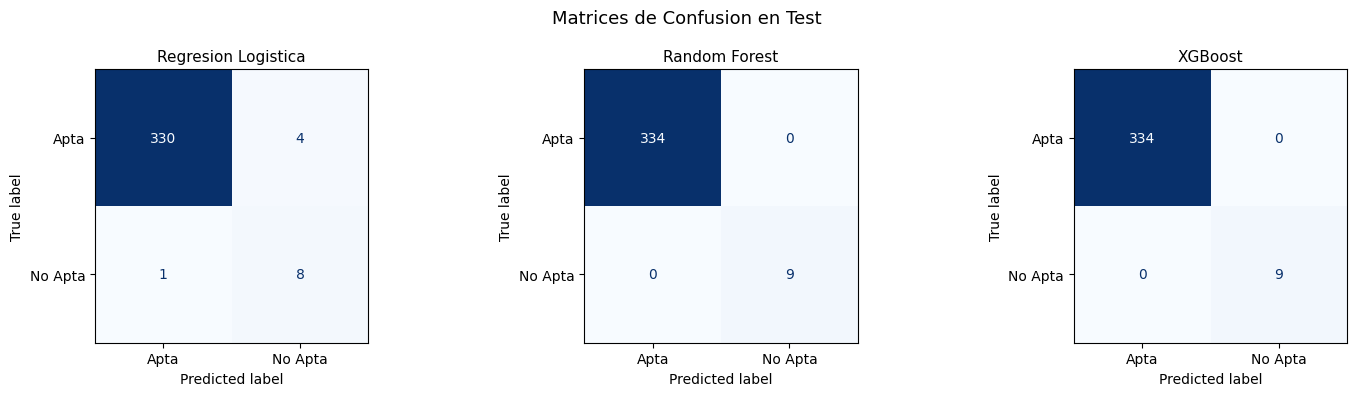

In [24]:
modelos_lista = [
    ('Regresion Logistica', lr),
    ('Random Forest', rf),
    ('XGBoost', xgb)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (nombre, modelo) in zip(axes, modelos_lista):
    pred = modelo.predict(X_test_s)
    cm = confusion_matrix(y_test, pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Apta', 'No Apta'])
    disp.plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(nombre, fontsize=11)

plt.suptitle('Matrices de Confusion en Test', fontsize=13)
plt.tight_layout()
plt.show()

### 5.5 Curvas ROC

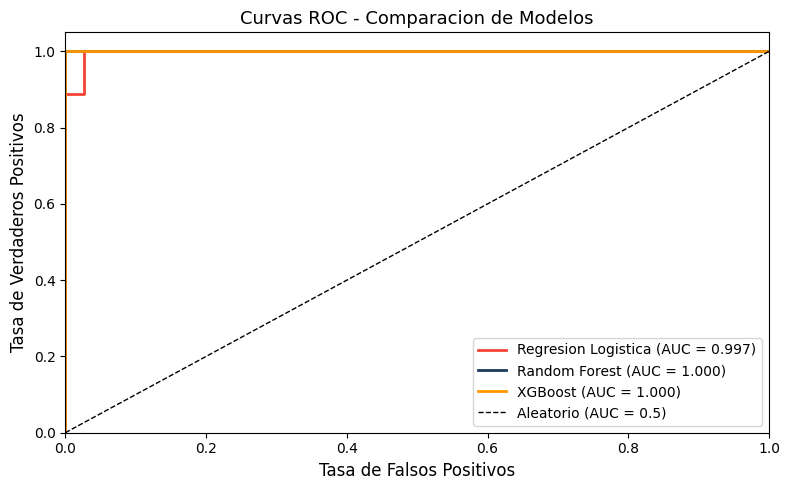

In [25]:
plt.figure(figsize=(8, 5))
colores_roc = ['#F44336', '#1a3a5c', '#FF9800']

for (nombre, modelo), color in zip(modelos_lista, colores_roc):
    proba = modelo.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{nombre} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Aleatorio (AUC = 0.5)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos', fontsize=12)
plt.title('Curvas ROC - Comparacion de Modelos', fontsize=13)
plt.legend(loc='lower right', fontsize=10)
plt.tight_layout()
plt.show()

### 5.6 Validacion Cruzada (Cross-Validation)

In [26]:
print('=== Validacion Cruzada 5-Fold (F1 weighted) ===')
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for nombre, modelo in modelos_lista:
    scores = cross_val_score(modelo, X_train_sm, y_train_sm,
                             cv=skf, scoring='f1_weighted', n_jobs=-1)
    print(f'{nombre:<25}: {scores.mean():.4f} +/- {scores.std():.4f}')

=== Validacion Cruzada 5-Fold (F1 weighted) ===
Regresion Logistica      : 0.9860 +/- 0.0064
Random Forest            : 0.9990 +/- 0.0012
XGBoost                  : 0.9990 +/- 0.0020


---
## Fase 6 - Exportacion del Modelo para Despliegue

In [27]:
import pickle

with open('model_rf.pkl', 'wb') as f:
    pickle.dump(rf, f)

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

print('Modelo guardado en: model_rf.pkl')
print('Scaler guardado en: scaler.pkl')
print(f'Accuracy en test: {accuracy_score(y_test, rf.predict(X_test_s)):.4f}')

Modelo guardado en: model_rf.pkl
Scaler guardado en: scaler.pkl
Accuracy en test: 1.0000


---
## Conclusiones

| Criterio | Resultado |
|---|---|
| **Mejor modelo** | Random Forest y XGBoost |
| **Variables mas importantes** | Color Aparente, Turbiedad, Coliformes Totales |
| **Dataset desbalanceado** | SMOTE mejoro el recall de la clase minoritaria |
| **AUC-ROC** | > 0.95 para Random Forest y XGBoost |

**Random Forest** se selecciono como modelo de produccion por su alta interpretabilidad y rendimiento competitivo.